# Obstacle Navigation — PPO

## Task description

**Task.** A circular robot (radius 0.2 m) must reach a goal in a 10 m × 10 m arena with randomly placed circular and rectangular obstacles. Each episode samples new obstacles, a collision-free start pose with random heading, and a goal at least 4 m away. A grid-based check ensures a collision-free path exists.

**State and observation.** The simulator state is the robot pose $q_t=(x_t,y_t,\theta_t)$, the goal $g$, the obstacle layout, and the last commanded velocities. The policy does not see the map or its exact pose. It receives a 40-dimensional noisy observation:

$$o_t=\left[\tfrac{\ell_{t,1}}{5},\ldots,\tfrac{\ell_{t,36}}{5},\ \tfrac{\hat d_t}{15},\ \tfrac{\hat\beta_t}{\pi},\ \tfrac{v_{t-1}}{0.8},\ \tfrac{\omega_{t-1}}{1.5}\right],$$

where $\ell_{t,i}$ are 36 LiDAR ranges (5 m maximum, noise std 0.02 m), $\hat d_t$ and $\hat\beta_t$ are the goal distance and bearing computed from a noisy pose estimate (std 0.01 m and 0.01 rad), and $v_{t-1},\omega_{t-1}$ are the last commanded velocities. The task is therefore partially observed.

**Observation margin.** With margin $m$, the LiDAR sees every obstacle inflated by $m$ (circle radius $r+m$; rectangle edges pushed out by $m$). Collisions still use the true obstacles, so the margin changes only what the robot perceives. The experiment compares $m=0$ and $m=0.1$ m.

**Action → waypoint.** The action $a_t\in[-1,1]^2$ is a waypoint offset in the robot frame, scaled by 1.5 m:

$$w_t=p_t+1.5\,R(\theta_t)\,a_t .$$

**Waypoint controller and dynamics.** A fixed controller drives the robot toward $w_t$. With $d_w$ the distance to the waypoint and $e_\theta$ the heading error,

$$v=\min(0.8,\,0.9\,d_w)\,\max(0,\cos e_\theta),\qquad \omega=\operatorname{clip}(2.5\,e_\theta,-1.5,1.5),$$

and the robot follows unicycle kinematics

$$\dot x=v\cos\theta,\qquad \dot y=v\sin\theta,\qquad \dot\theta=\omega .$$

Each action lasts 0.5 s (ten 0.05 s controller updates, integrated in small steps with collision checks). The controller uses the true pose; there is no motor lag or wheel slip.

**Reward and outcomes.** With $d_t$ the true goal distance,

$$r_t=10\,(d_t-d_{t+1})-0.05-20\cdot\mathbf 1_{\text{collision}}+50\cdot\mathbf 1_{\text{success}} .$$

An episode ends in **success** (within 0.35 m of the goal), **collision** (with an obstacle or wall), or **timeout** (160 actions, treated as truncation rather than failure).

Full details: [docs/navigation.md](../docs/navigation.md).

## 1. Environment setup

Mount Google Drive, locate the project, install dependencies, and register the package import path. Local execution uses the project root or its `notebooks/` directory.

In [1]:
from pathlib import Path
import sys

# Project location.
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive/rl_examples")  # Google Drive project path.
else:
    PROJECT = Path.cwd()
    if not (PROJECT / "pyproject.toml").exists():
        PROJECT = PROJECT.parent

assert (PROJECT / "pyproject.toml").exists(), f"Project not found: {PROJECT}"
%pip -q install "swig>=4.2,<5"
%pip -q install -e "{PROJECT}"

assert (PROJECT / "rl_examples" / "__init__.py").exists(), "Python package directory missing"
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
import importlib
importlib.invalidate_caches()

Mounted at /content/drive
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for rl-examples (pyproject.toml) ... done


## 2. Imports

Load configuration, training, evaluation, simulation, and plotting functions. Limit PyTorch CPU execution to two threads.

In [2]:
import os
os.environ.setdefault("SDL_VIDEODRIVER", "dummy")
from dataclasses import replace
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Video
from rl_examples.configs.settings import NavigationConfig, LanderConfig, SACConfig, PPOConfig, TrainingConfig
from rl_examples.configs.smoke import smoke_settings
from rl_examples.training.runner import run_experiment
from rl_examples.evaluation.comparison import compare_runs
from rl_examples.evaluation.metrics import paired_efficiency
from rl_examples.simulation.examples import simulate_runs
from rl_examples.visualization.plots import plot_learning_curves, plot_trajectories
from rl_examples.utils.labels import run_labels, format_results

torch.set_num_threads(2)

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 3. Experiment configuration

Set environment parameters, algorithm hyperparameters, training budgets, and scenario seeds. `SMOKE_ONLY=True` runs a short pipeline check; `False` enables full training. `MODE="load"` reads completed runs with matching settings. Results are stored under `outputs/`.

In [4]:
SMOKE_ONLY = False  # True: pipeline check; False: full training.
MODE = "train"     # "train" or "load".
RUN_NAME = "navigation_ppo_v1"  # Experiment identifier.
RUN_HELD_OUT_TEST = False

conditions = {
    "margin_0": NavigationConfig(lidar_margin=0.0, n_circles=3, n_rectangles=2),
    "margin_010": NavigationConfig(lidar_margin=0.10, n_circles=3, n_rectangles=2),
}
USE_CURRICULUM = True
stages = {name: [replace(env, n_circles=c, n_rectangles=r)
                 for c, r in ((0, 0), (1, 0), (3, 2))]
          for name, env in conditions.items()} if USE_CURRICULUM else None
agent_config = PPOConfig(learning_rate=3e-4, n_steps=1000, batch_size=250, hidden_sizes=(256, 256))

training_config = TrainingConfig(
    steps_per_stage=10_000 if USE_CURRICULUM else 30_000,
    eval_every=2000, seed=42, early_stopping=False,
    min_steps=24_000, patience=5, min_delta=0.0,
    validation_a=tuple(range(20000, 20025)),
    validation_b=tuple(range(21000, 21025)),
    test_seeds=tuple(range(30000, 30100)),
)

if SMOKE_ONLY:
    conditions, agent_config, training_config, stages = smoke_settings(
        conditions, agent_config, training_config, stages)
OUTPUT = PROJECT / "outputs" / (RUN_NAME + ("_smoke" if SMOKE_ONLY else ""))
print(OUTPUT)

/content/drive/MyDrive/rl_examples/outputs/navigation_ppo_v1


## 4. Training

Train an independent policy for each condition and evaluate after each training interval. Validation A tracks performance; validation B selects the checkpoint. Optional early stopping applies in the final curriculum stage.

In [5]:
runs = run_experiment(conditions, agent_config, training_config, OUTPUT, stages=stages, mode=MODE)

PPO | margin = 0 m | 2,000 steps | B success=0% | return=11.2


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


PPO | margin = 0 m | 4,000 steps | B success=4% | return=40.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


PPO | margin = 0 m | 6,000 steps | B success=40% | return=60.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (50 outputs left out)

PPO | margin = 0.1 m | 28,000 steps | B success=96% | return=107.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


PPO | margin = 0.1 m | 30,000 steps | B success=92% | return=104.2


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 5. Learning curves

Plot exploratory training returns and deterministic validation returns and success rates. Vertical lines mark curriculum transitions.

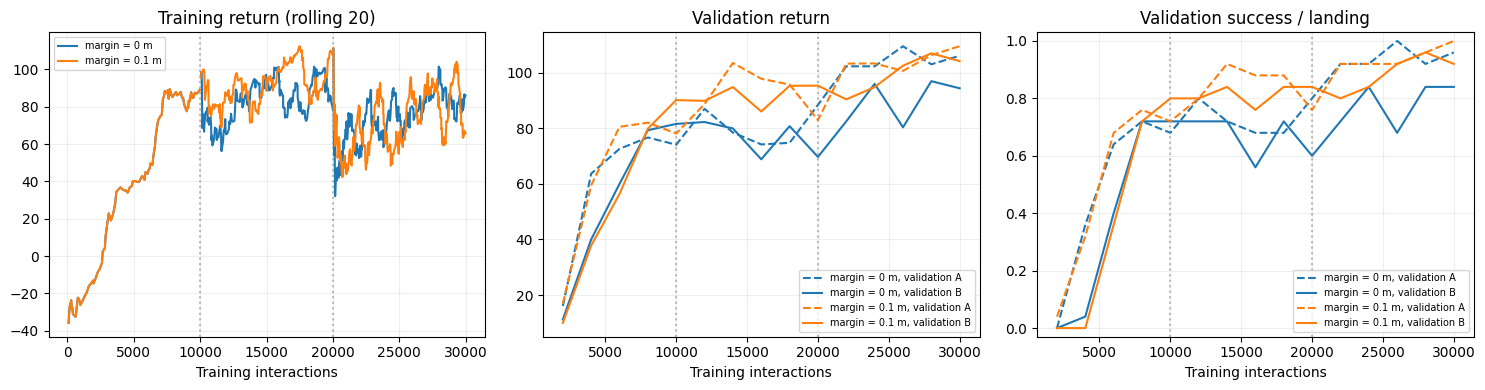

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [6]:
labels = run_labels(runs)
fig = plot_learning_curves(runs)
fig.savefig(OUTPUT / "learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Checkpoint validation

Compare selected and final checkpoints on validation B. Report efficiency on scenarios completed successfully by both selected policies. These selection-panel scores are not held-out test estimates.

In [7]:
summary, episodes = compare_runs(runs, training_config.validation_b)
display(format_results(summary, labels))
paired = paired_efficiency(episodes[episodes.checkpoint == "best"])
display(format_results(paired, labels))
summary.to_csv(OUTPUT / "validation_summary.csv", index=False)

,condition,checkpoint,checkpoint_steps,episodes,mean_return,success_rate,collision_rate,timeout_rate,successful_mean_steps,successful_mean_path_length_m
0,margin = 0 m,best,28000,25,96.943,0.84,0.12,0.04,35.143,8.536
1,margin = 0 m,final,30000,25,94.392,0.84,0.16,0.00,37.810,8.952
2,margin = 0.1 m,best,28000,25,106.963,0.96,0.04,0.00,30.667,8.152
3,margin = 0.1 m,final,30000,25,104.162,0.92,0.04,0.04,34.783,8.701


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,condition,common_successes,mean_steps,mean_path_length_m
0,margin = 0 m,21,35.143,8.536
1,margin = 0.1 m,21,29.619,8.166


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 7. Trajectory comparison

Simulate the selected policies on three fixed validation scenarios. Rows correspond to scenario seeds; columns correspond to conditions. Each panel reports the episode outcome.

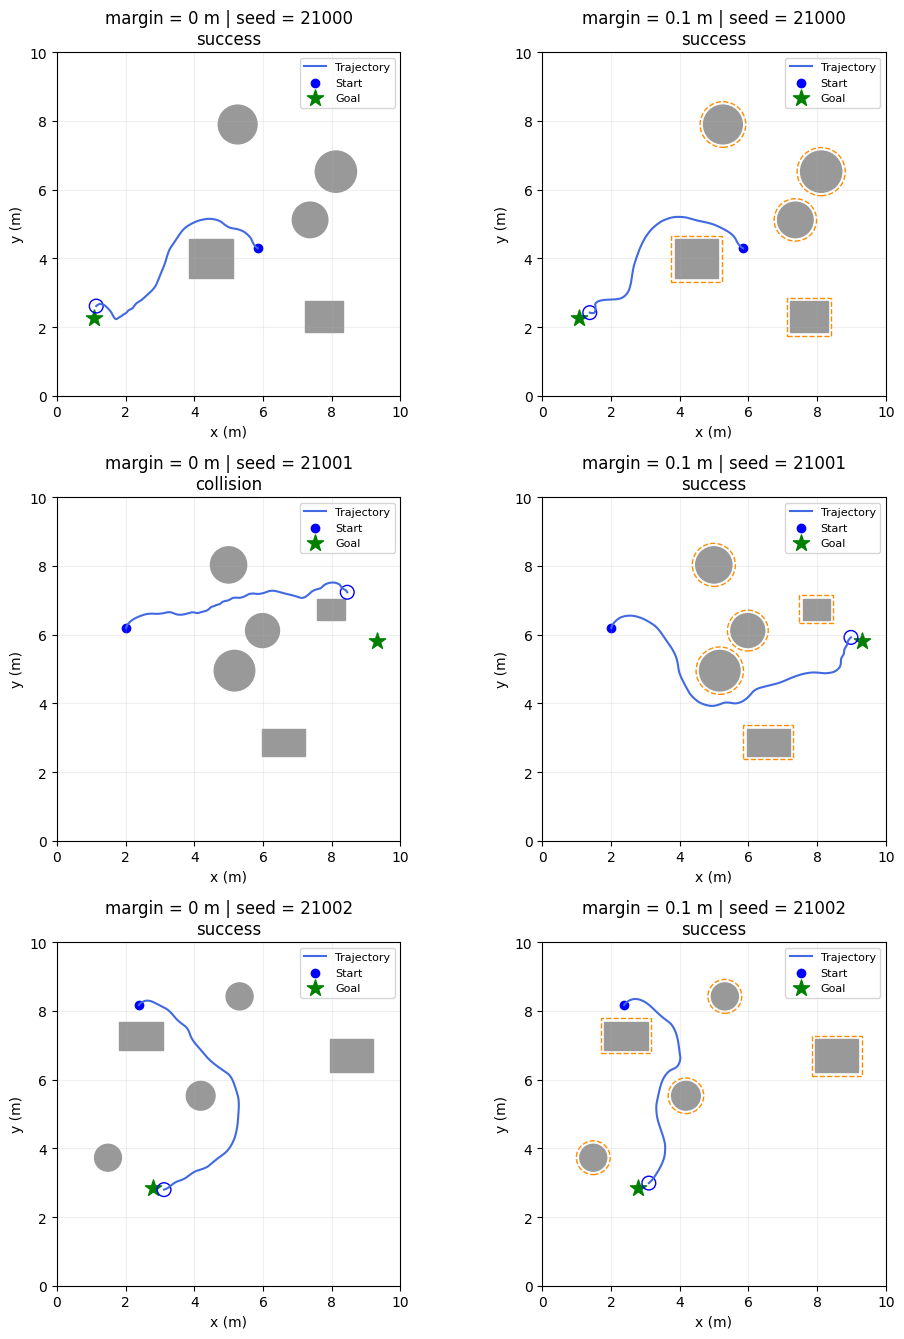

In [8]:
SCENARIO_SEEDS = (21000, 21001, 21002)
rollouts = simulate_runs(runs, seeds=SCENARIO_SEEDS)
fig = plot_trajectories(rollouts)
fig.savefig(OUTPUT / "trajectories.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Video export

Export selected-policy rollouts as MP4 files with PNG previews and JSON run metadata. Enable after full training. Navigation is sampled once per high-level action (2 fps); LunarLander is recorded at 50 fps.

In [9]:
RECORD_VIDEOS = True
VIDEO_SEEDS = (21000, 21001)
if RECORD_VIDEOS:
    if SMOKE_ONLY:
        raise ValueError("Video demonstrations require SMOKE_ONLY=False and completed training")
    videos = simulate_runs(runs, seeds=VIDEO_SEEDS, video_dir=OUTPUT / "videos")
    for condition, scenarios in videos.items():
        for seed, result in scenarios.items():
            print(f"{labels[condition]} | seed = {seed} | {result['metrics']['outcome']}")
            display(Video(str(result["video_path"]), embed=True))

margin = 0 m | seed = 21000 | success


margin = 0 m | seed = 21001 | collision


margin = 0.1 m | seed = 21000 | success


margin = 0.1 m | seed = 21001 | success


## 9. Held-out evaluation

Evaluate selected checkpoints on reserved test scenarios after fixing the experiment settings. Report outcomes and paired efficiency without further checkpoint selection.

In [ ]:
if RUN_HELD_OUT_TEST:
    if SMOKE_ONLY:
        raise ValueError("Held-out evaluation requires full training")
    test_summary, test_episodes = compare_runs(
        runs, training_config.test_seeds, split="test", checkpoints=("best",))
    display(format_results(test_summary, labels))
    display(format_results(paired_efficiency(test_episodes), labels))
    test_summary.to_csv(OUTPUT / "test_summary.csv", index=False)
else:
    print("Held-out evaluation disabled.")